# Exploratory Data Analysis (EDA)

## 1. Setup

### 1.1 Imports

In [18]:
from folium.plugins import HeatMap
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
import holidays
import folium
import ast
import os

from itertools import chain
from math import radians, sin, cos, sqrt, atan2

### 1.2 Helper Functions

In [19]:
def compute_distance(polyline) -> float:
    """
    Compute the total distance along a polyline in kilometers.

    Args:
        polyline: A sequence of [longitude, latitude] coordinate points.

    Returns:
        float: The total distance along the polyline. Returns 0 if the
        polyline contains fewer than two points.
    """
    if len(polyline) < 2:
        return 0

    distance = 0
    for i in range(len(polyline) - 1):
        distance += haversine(polyline[i], polyline[i + 1])

    return distance

def haversine(p1, p2) -> float:
    """
    Calculate the great-circle distance between two [longitude, latitude] points.

    Returns:
        float: Distance between the two points in kilometers.
    """
    lon1, lat1 = p1
    lon2, lat2 = p2

    R = 6371

    dlat = radians(lat2 - lat1)
    dlon = radians(lon2 - lon1)

    a = (
        sin(dlat / 2) ** 2
        + cos(radians(lat1))
        * cos(radians(lat2))
        * sin(dlon / 2) ** 2
    )

    return 2 * R * atan2(sqrt(a), sqrt(1 - a))

def is_within_city_bounds(polyline) -> bool:
    """
    Check whether all points in a parsed polyline are within the city bounds.
    """
    if not polyline:
        return False

    return all(
        CITY_BOUNDS[0] <= lon <= CITY_BOUNDS[1]
        and CITY_BOUNDS[2] <= lat <= CITY_BOUNDS[3]
        for lon, lat in polyline
    )

def has_large_jump(polyline, max_jump_km=1.0) -> bool:
    """
    Detect consecutive GPS points farther apart than max_jump_km.

    The polyline must contain parsed [longitude, latitude] points.
    """
    if len(polyline) < 2:
        return False

    for i in range(len(polyline) - 1):
        dist = haversine(polyline[i], polyline[i + 1])
        if dist > max_jump_km:
            return True

    return False

def get_correct_day_type(date, holiday_dates, day_before_holiday) -> str:
    """
    Determine the correct day type for a given date.
    
    Args:
        date (datetime.date): The date to check.
        holiday_dates (set): A set of holiday dates.
        day_before_holiday (set): A set of dates that are the day before holidays.
    Returns:
        str: "A" for normal days, "B" for holidays, "C" for days before holidays.
    """
    
    if date in holiday_dates:
        return "B"
    elif date in day_before_holiday:
        return "C"
    else:
        return "A"

def compute_iqr_bounds(values, k=1.5) -> dict:
    """
    Compute the IQR and lower/upper outlier fences for a numeric series.

    Args:
        values (pd.Series): The numeric values to analyse.
        k (float): The IQR multiplier used for the fences (1.5 by default).

    Returns:
        dict: Q1, Q3, IQR, lower and upper fences, and outlier counts.
    """
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - k * iqr
    upper = q3 + k * iqr

    n_lower = (values < lower).sum()
    n_upper = (values > upper).sum()

    return {
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower fence": lower,
        "Upper fence": upper,
        "Outliers below": n_lower,
        "Outliers above": n_upper,
        "Total outliers": n_lower + n_upper,
        "Outlier share (%)": 100 * (n_lower + n_upper) / len(values)
    }

def plot_outlier_boxplot(values, title, xlabel, output_path) -> dict:
    """
    Plot two separate boxplots of a numeric series, one with and one without
    outliers, mark the IQR fences, save both figures and return the IQR statistics.

    Args:
        values (pd.Series): The numeric values to plot.
        title (str): The title of the plot.
        xlabel (str): The label for the x-axis.
        output_path (str): The file path to save the plot with outliers. The plot
            without outliers is saved with "_without_outliers" added to the name.
    Returns:
        dict: The IQR statistics computed by compute_iqr_bounds.
    """
    bounds = compute_iqr_bounds(values)
    root, extension = os.path.splitext(output_path)

    for show_fliers, subtitle, path in [
        (True, "All trips", output_path),
        (False, "Without outliers", f"{root}_without_outliers{extension}")
    ]:
        fig, ax = plt.subplots(figsize=(10, 3.5))
        ax.boxplot(
            values,
            vert=False,
            whis=1.5,
            showfliers=show_fliers,
            flierprops={"marker": ".", "markersize": 2, "alpha": 0.3}
        )
        ax.axvline(bounds["Upper fence"], color="red", linestyle="--", label="Upper fence (Q3 + 1.5·IQR)")
        if bounds["Lower fence"] >= values.min():
            ax.axvline(bounds["Lower fence"], color="orange", linestyle="--", label="Lower fence (Q1 − 1.5·IQR)")
        ax.set_title(
            f"{title} – {subtitle}\n"
            f"{bounds['Total outliers']:,} outliers detected "
            f"({bounds['Outlier share (%)']:.2f}% of {len(values):,} trips)"
        )
        ax.set_xlabel(xlabel)
        ax.set_yticks([])
        ax.legend(loc="upper right")
        plt.tight_layout()
        plt.savefig(path, bbox_inches="tight")
        plt.show()

    return bounds

def haversine_vectorized(lon1, lat1, lon2, lat2) -> np.ndarray:
    """
    Calculate great-circle distances between arrays of [longitude, latitude] points.

    Args:
        lon1 (np.ndarray): Longitudes of the start points in degrees.
        lat1 (np.ndarray): Latitudes of the start points in degrees.
        lon2 (np.ndarray): Longitudes of the end points in degrees.
        lat2 (np.ndarray): Latitudes of the end points in degrees.
    Returns:
        np.ndarray: Distances between the point pairs in kilometers.
    """
    R = 6371

    lon1, lat1, lon2, lat2 = map(np.radians, (lon1, lat1, lon2, lat2))
    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2

    return 2 * R * np.arcsin(np.sqrt(np.clip(a, 0, 1)))

def compute_speed_features(polylines, speed_limit_kmh, interval_seconds) -> pd.DataFrame:
    """
    Compute segment speed features for a list of parsed polylines.

    Args:
        polylines (list): Parsed polylines, each a list of [longitude, latitude] points.
        speed_limit_kmh (float): Segment speed above which a segment counts as a violation.
        interval_seconds (float): Time between consecutive GPS points in seconds.
    Returns:
        pd.DataFrame: One row per polyline with valid_segments, max_segment_speed,
        speed_violation_count, speed_violation_ratio and p95_segment_speed. The
        speed columns are NaN for trips without valid segments.
    """
    n_trips = len(polylines)
    n_points = np.fromiter((len(polyline) for polyline in polylines), dtype=np.int64, count=n_trips)

    coords = np.fromiter(
        chain.from_iterable(chain.from_iterable(polylines)),
        dtype=np.float64,
        count=2 * int(n_points.sum())
    ).reshape(-1, 2)
    lon, lat = coords[:, 0], coords[:, 1]
    point_trip = np.repeat(np.arange(n_trips), n_points)

    valid_point = np.isfinite(lon) & np.isfinite(lat) & (np.abs(lon) <= 180) & (np.abs(lat) <= 90)
    valid_segment = (point_trip[1:] == point_trip[:-1]) & valid_point[1:] & valid_point[:-1]

    segment_trip = point_trip[1:][valid_segment]
    segment_distance = haversine_vectorized(
        lon[:-1][valid_segment], lat[:-1][valid_segment],
        lon[1:][valid_segment], lat[1:][valid_segment]
    )
    segment_speed = segment_distance / (interval_seconds / 3600)

    n_segments = np.bincount(segment_trip, minlength=n_trips)
    n_violations = np.bincount(
        segment_trip,
        weights=(segment_speed > speed_limit_kmh).astype(np.float64),
        minlength=n_trips
    )

    # Sort speeds within each trip so max and percentile can be read by position
    order = np.lexsort((segment_speed, segment_trip))
    sorted_speed = segment_speed[order]
    has_segments = n_segments > 0
    starts = (np.cumsum(n_segments) - n_segments)[has_segments]
    counts = n_segments[has_segments]

    max_speed = np.full(n_trips, np.nan)
    max_speed[has_segments] = sorted_speed[starts + counts - 1]

    # Linear interpolation between the closest ranks, same as np.percentile
    position = 0.95 * (counts - 1)
    lower = np.floor(position).astype(np.int64)
    upper = np.minimum(lower + 1, counts - 1)
    fraction = position - lower
    p95_speed = np.full(n_trips, np.nan)
    p95_speed[has_segments] = (
        sorted_speed[starts + lower]
        + fraction * (sorted_speed[starts + upper] - sorted_speed[starts + lower])
    )

    violation_count = np.where(has_segments, n_violations, np.nan)
    with np.errstate(divide="ignore", invalid="ignore"):
        violation_ratio = np.where(has_segments, n_violations / n_segments, np.nan)

    return pd.DataFrame({
        "valid_segments": n_segments,
        "max_segment_speed": max_speed,
        "speed_violation_count": violation_count,
        "speed_violation_ratio": violation_ratio,
        "p95_segment_speed": p95_speed
    })

def summarize_thresholds(values, thresholds, labels) -> pd.DataFrame:
    """
    Count how many values exceed each threshold.

    Args:
        values (pd.Series): The values to compare, without missing values.
        thresholds (list): The thresholds to compare against (strictly greater than).
        labels (list[str]): The display label for each threshold.
    Returns:
        pd.DataFrame: The number and percentage of values above each threshold.
    """
    return pd.DataFrame({
        "Threshold": labels,
        "Trips": [int((values > threshold).sum()) for threshold in thresholds],
        "Share of valid trips (%)": [100 * (values > threshold).mean() for threshold in thresholds]
    })

def plot_share_bar_chart(values, bins, labels, title, xlabel, output_path,
                         color="#4C78A8", highlight_from=None, highlight_color="#E45756") -> pd.Series:
    """
    Group values into bins and plot the number of trips per bin as a bar chart,
    with each bar labelled by its percentage share of all values.

    Args:
        values (pd.Series): The values to group, without missing values.
        bins (list): The bin edges passed to pd.cut (right-inclusive).
        labels (list[str]): The label of each bin.
        title (str): The title of the plot.
        xlabel (str): The label for the x-axis.
        output_path (str): The file path to save the plot image.
        color (str): The colour of the bars.
        highlight_from (str | None): The first bin label to colour with highlight_color,
            e.g. the first bin above the speed limit. None colours every bar the same.
        highlight_color (str): The colour of the highlighted bars.
    Returns:
        pd.Series: The number of trips per bin.
    """
    groups = (
        pd.cut(values, bins=bins, labels=labels, include_lowest=True)
        .value_counts(sort=False)
        .reindex(labels, fill_value=0)
    )
    shares = 100 * groups / len(values)

    colors = [color] * len(labels)
    if highlight_from is not None:
        first = labels.index(highlight_from)
        colors[first:] = [highlight_color] * (len(labels) - first)

    ax = groups.plot(
        kind="bar",
        figsize=(12, 5),
        color=colors,
        title=title,
        xlabel=xlabel,
        rot=0
    )

    ax.set_yscale("log")
    ax.set_ylabel("Number of Trips (log scale)")
    for patch, value, share in zip(ax.patches, groups, shares):
        if value > 0:
            label = f"{share:.2f}%" if share >= 0.01 else "< 0.01%"
            ax.annotate(label, (patch.get_x() + patch.get_width() / 2, value),
                        ha="center", va="bottom", fontsize=8)

    plt.tight_layout()
    plt.savefig(output_path, bbox_inches="tight")
    plt.show()

    return groups

### 1.3 Constants

In [20]:
DATA_PATH = "data/porto.csv"
RESULT_FOLDER = "../src/results/figures/"
TABLE_FOLDER = "../src/results/tables/"
SPEED_DATASET_PATH = "data/porto_speed_anomalies.csv"

SUBSET_SIZE = 15000

PORTO_CENTER = [-8.6291, 41.1579]       # Porto city center: [longitude, latitude]
MAIN_STATION = [-8.610454, 41.145557]   # Porto Campanhã: [longitude, latitude]
AIRPORT = [-8.670828, 41.236818]        # Francisco Sá Carneiro Airport: [longitude, latitude]

CITY_BOUNDS = (-8.65, -8.55, 41.13, 41.18)
MAX_PORTO_TRIP_DISTANCE_KM = 50
MAX_PORTO_TRIP_DURATION_MINUTES = 60
MAX_PORTO_AVERAGE_SPEED_KMH = 100

CONGESTION_DISTANCE_KM = 0.02
CONGESTION_MIN_DURATION_SECONDS = 60

GPS_INTERVAL_SECONDS = 15
SPEED_LIMIT_KMH = 120
SPEED_CHUNK_SIZE = 100_000

### 1.3 Load Dataset

In [21]:
df = pd.read_csv(DATA_PATH)

## 2. Dataset Overview

In [22]:
print("Shape:", df.shape)
print("Number of taxi drivers:", df['TAXI_ID'].nunique())

Shape: (1710670, 9)
Number of taxi drivers: 448


In [23]:
column_info = pd.DataFrame({
    "Column": df.columns,
    "Data type": df.dtypes.astype(str),
    "Non-null values": df.notna().sum(),
    "Missing values": df.isna().sum(),
    "Unique values": df.nunique()
})

display(column_info)

,Column,Data type,Non-null values,Missing values,Unique values
TRIP_ID,TRIP_ID,int64,1710670,0,1710589
CALL_TYPE,CALL_TYPE,str,1710670,0,3
ORIGIN_CALL,ORIGIN_CALL,float64,364770,1345900,57105
ORIGIN_STAND,ORIGIN_STAND,float64,806579,904091,63
TAXI_ID,TAXI_ID,int64,1710670,0,448
TIMESTAMP,TIMESTAMP,int64,1710670,0,1655366
DAY_TYPE,DAY_TYPE,str,1710670,0,1
MISSING_DATA,MISSING_DATA,bool,1710670,0,2
POLYLINE,POLYLINE,str,1710670,0,1703650


In [24]:
display(df.head())

,TRIP_ID,CALL_TYPE,ORIGIN_CALL,ORIGIN_STAND,TAXI_ID,TIMESTAMP,DAY_TYPE,MISSING_DATA,POLYLINE
0,1372636858620000589,C,NaN,NaN,20000589,1372636858,A,False,"[[-8.618643,41.141412],[-8.618499,41.141376],[..."
1,1372637303620000596,B,NaN,7.0,20000596,1372637303,A,False,"[[-8.639847,41.159826],[-8.640351,41.159871],[..."
2,1372636951620000320,C,NaN,NaN,20000320,1372636951,A,False,"[[-8.612964,41.140359],[-8.613378,41.14035],[-..."
3,1372636854620000520,C,NaN,NaN,20000520,1372636854,A,False,"[[-8.574678,41.151951],[-8.574705,41.151942],[..."
4,1372637091620000337,C,NaN,NaN,20000337,1372637091,A,False,"[[-8.645994,41.18049],[-8.645949,41.180517],[-..."


In [25]:
display(df.describe(include="all"))

,TRIP_ID,CALL_TYPE,ORIGIN_CALL,ORIGIN_STAND,TAXI_ID,TIMESTAMP,DAY_TYPE,MISSING_DATA,POLYLINE
count,1.710670e+06,1710670,364770.000000,806579.000000,1.710670e+06,1.710670e+06,1710670,1710670,1710670
unique,NaN,3,NaN,NaN,NaN,NaN,1,2,1703650
top,NaN,B,NaN,NaN,NaN,NaN,A,False,[]
freq,NaN,817881,NaN,NaN,NaN,NaN,1710670,1710660,5901
mean,1.388622e+18,NaN,24490.363018,30.272381,2.000035e+07,1.388622e+09,NaN,NaN,NaN
std,9.180944e+15,NaN,19624.290043,17.747840,2.112405e+02,9.180944e+06,NaN,NaN,NaN
min,1.372637e+18,NaN,2001.000000,1.000000,2.000000e+07,1.372637e+09,NaN,NaN,NaN
25%,1.380731e+18,NaN,6593.000000,15.000000,2.000017e+07,1.380731e+09,NaN,NaN,NaN
50%,1.388493e+18,NaN,18755.000000,27.000000,2.000034e+07,1.388493e+09,NaN,NaN,NaN
75%,1.396750e+18,NaN,40808.000000,49.000000,2.000052e+07,1.396750e+09,NaN,NaN,NaN


## 2. Data Preparation

In [26]:
df["DATETIME"] = pd.to_datetime(df["TIMESTAMP"], unit="s", utc=True).dt.tz_convert("Europe/Lisbon")
df["DATE"] = df["DATETIME"].dt.date
df["POLYLINE"] = df["POLYLINE"].apply(ast.literal_eval)
df["GPS_POINTS"] = df["POLYLINE"].apply(len)
df["DURATION"] = (df["GPS_POINTS"] - 1) * 15
df["DISTANCE"] = df["POLYLINE"].apply(compute_distance)
df["AVERAGE_SPEED"] = df["DISTANCE"] / (df["DURATION"] / 3600)

df["MISSING_FLAG"] = ( 
    df["MISSING_DATA"]
    .astype(str)
    .str.strip()
    .str.lower()
    .eq("true")
)

df["EMPTY_POLYLINE"] = df["POLYLINE"].map(len).eq(0)
df["MISSING_LOCATION"] = df["MISSING_FLAG"] | df["EMPTY_POLYLINE"]

## 3. Distribution of Call Types

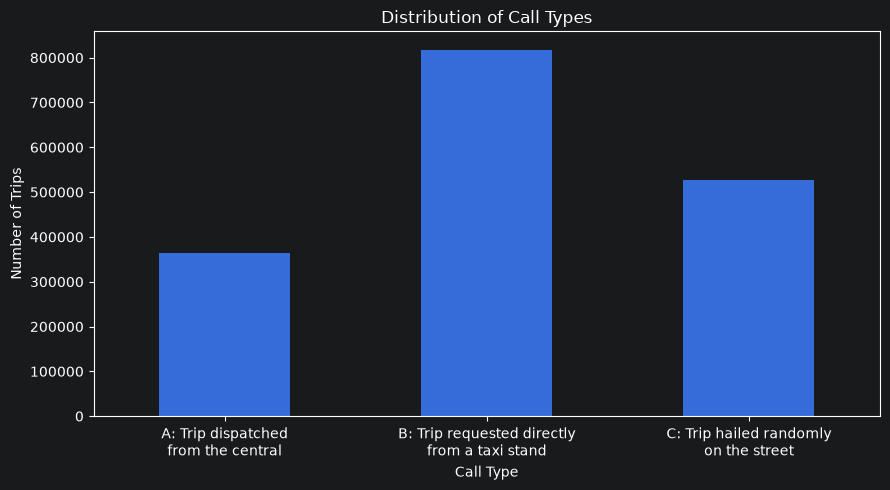

In [27]:
call_type_names = {
    "A": "A: Trip dispatched\nfrom the central",
    "B": "B: Trip requested directly\nfrom a taxi stand",
    "C": "C: Trip hailed randomly\non the street"
}

call_type_counts = (
    df["CALL_TYPE"]
    .value_counts()
    .reindex(["A", "B", "C"], fill_value=0)
)

call_type_counts.index = call_type_counts.index.map(call_type_names)

ax = call_type_counts.plot(
    kind="bar",
    figsize=(9, 5),
    title="Distribution of Call Types",
    xlabel="Call Type",
    ylabel="Number of Trips",
    rot=0
)

ax.ticklabel_format(style="plain", axis="y")

plt.tight_layout()
plt.savefig(RESULT_FOLDER + "call_type_distribution.png", bbox_inches="tight")
plt.show()

## 4. Distribution of Day Types

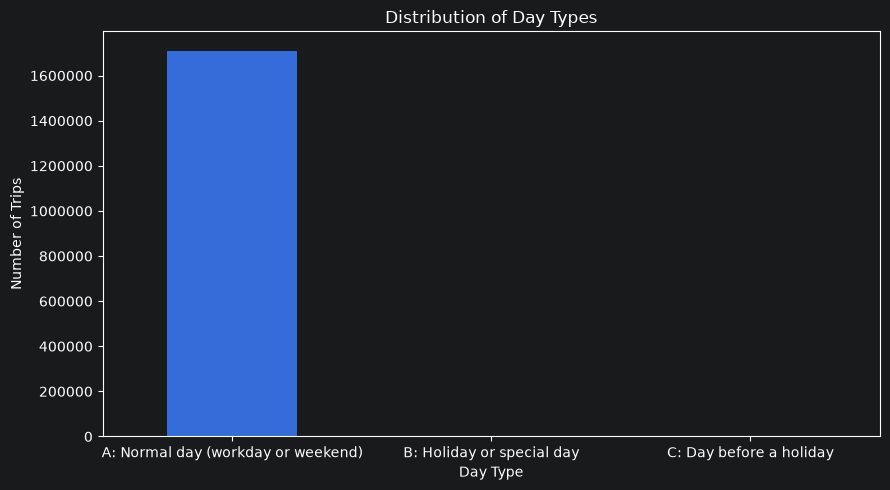

In [28]:
day_type_names = {
    "A": "A: Normal day (workday or weekend)",
    "B": "B: Holiday or special day",
    "C": "C: Day before a holiday"
}

day_type_counts = (
    df["DAY_TYPE"]
    .value_counts()
    .reindex(["A", "B", "C"], fill_value=0)
)

day_type_counts.index = day_type_counts.index.map(day_type_names)

ax = day_type_counts.plot(
    kind="bar",
    figsize=(9, 5),
    title="Distribution of Day Types",
    xlabel="Day Type",
    ylabel="Number of Trips",
    rot=0
)

ax.ticklabel_format(style="plain", axis="y")

plt.tight_layout()
plt.savefig(RESULT_FOLDER + "day_type_distribution.png", bbox_inches="tight")
plt.show()

## 5. Distribution of Trips at Different Times

### 5.1 Number of Trips per Hour

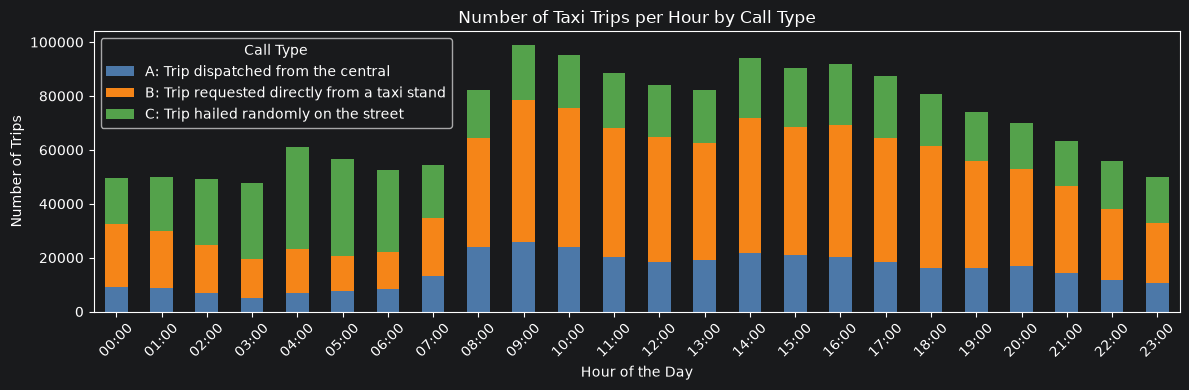

In [29]:
call_type_counts_per_hour = pd.crosstab(
    df["DATETIME"].dt.hour,
    df["CALL_TYPE"]
).reindex(index=range(24), columns=["A", "B", "C"], fill_value=0)

call_type_descriptions = [
    "A: Trip dispatched from the central",
    "B: Trip requested directly from a taxi stand",
    "C: Trip hailed randomly on the street"
]

ax = call_type_counts_per_hour.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 4),
    color={"A": "#4C78A8", "B": "#F58518", "C": "#54A24B"},
    title="Number of Taxi Trips per Hour by Call Type",
    xlabel="Hour of the Day",
    ylabel="Number of Trips"
)

ax.set_xticklabels(
    [f"{hour:02d}:00" for hour in range(24)],
    rotation=45
)
ax.legend(title="Call Type", labels=call_type_descriptions)
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "number_of_taxi_trips_per_hour.png", bbox_inches="tight")
plt.show()

### 5.2 Number of Trips per Weekday

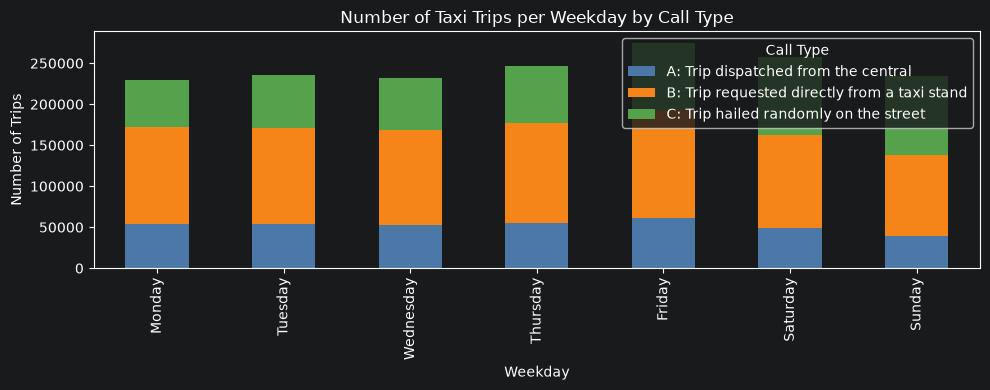

In [30]:
weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

call_type_counts_per_weekday = pd.crosstab(
    df["DATETIME"].dt.day_name(),
    df["CALL_TYPE"]
).reindex(index=weekday_order, columns=["A", "B", "C"], fill_value=0)

call_type_descriptions = [
    "A: Trip dispatched from the central",
    "B: Trip requested directly from a taxi stand",
    "C: Trip hailed randomly on the street"
]

ax = call_type_counts_per_weekday.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 4),
    color={"A": "#4C78A8", "B": "#F58518", "C": "#54A24B"},
    title="Number of Taxi Trips per Weekday by Call Type",
    xlabel="Weekday",
    ylabel="Number of Trips"
)

ax.legend(title="Call Type", labels=call_type_descriptions)
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "number_of_taxi_trips_per_day.png", bbox_inches="tight")
plt.show()

### 5.3 Number of Trips per Month

/var/folders/sl/p1m0kw051hx13qw76x1ct7140000gn/T/ipykernel_39133/575975033.py:2: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df["DATETIME"].dt.to_period("M"),


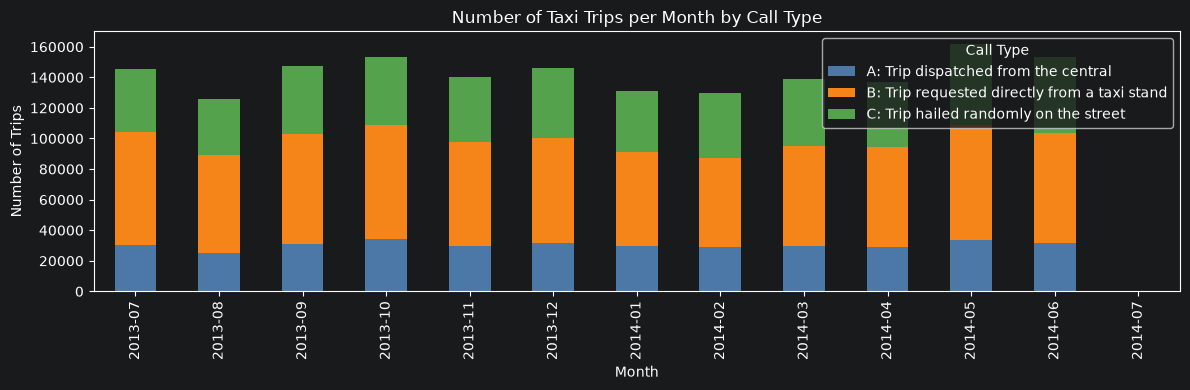

In [31]:
call_type_counts_per_month = pd.crosstab(
    df["DATETIME"].dt.to_period("M"),
    df["CALL_TYPE"]
).reindex(columns=["A", "B", "C"], fill_value=0)

call_type_descriptions = [
    "A: Trip dispatched from the central",
    "B: Trip requested directly from a taxi stand",
    "C: Trip hailed randomly on the street"
]

ax = call_type_counts_per_month.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 4),
    color={"A": "#4C78A8", "B": "#F58518", "C": "#54A24B"},
    title="Number of Taxi Trips per Month by Call Type",
    xlabel="Month",
    ylabel="Number of Trips"
)

ax.legend(title="Call Type", labels=call_type_descriptions)
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "number_of_taxi_trips_per_month.png", bbox_inches="tight")
plt.show()

## 6. Distribution of GPS Points per Trip

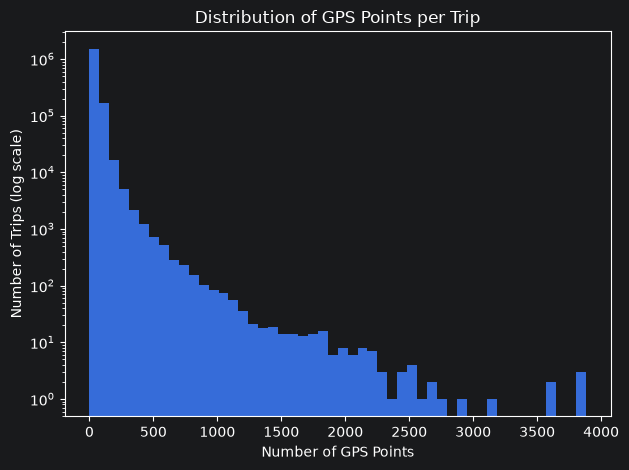

In [32]:
ax = df["GPS_POINTS"].plot(
    kind="hist",
    bins=50,
    title="Distribution of GPS Points per Trip",
    xlabel="Number of GPS Points"
)

ax.set_yscale("log")
ax.set_ylabel("Number of Trips (log scale)")
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "gps_points_distribution.png", bbox_inches="tight")
plt.show()

## 7. Distribution of Distance per Trip

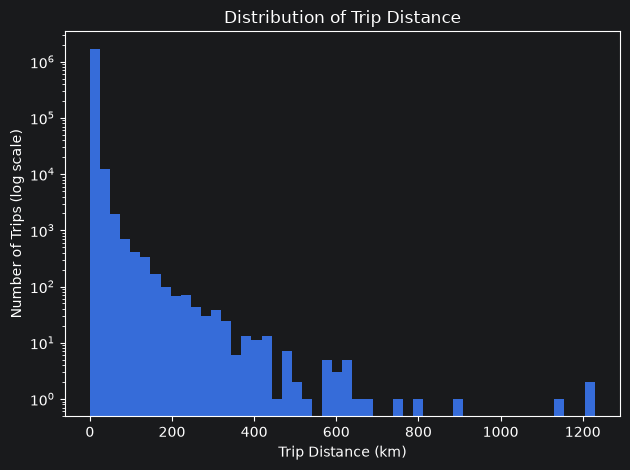

In [33]:
ax = df["DISTANCE"].plot(
    kind="hist",
    bins=50,
    title="Distribution of Trip Distance",
    xlabel="Trip Distance (km)"
)

ax.set_yscale("log")
ax.set_ylabel("Number of Trips (log scale)")
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "trip_distance_distribution.png", bbox_inches="tight")
plt.show()

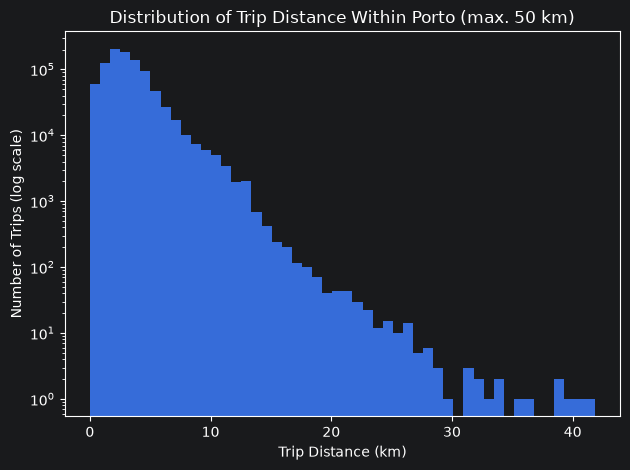

In [34]:
MAX_PORTO_TRIP_DISTANCE_KM = 50

porto_trips = df[
    (~df["MISSING_FLAG"])
    & df["POLYLINE"].apply(is_within_city_bounds)
    & (df["DISTANCE"] <= MAX_PORTO_TRIP_DISTANCE_KM)
]

ax = porto_trips["DISTANCE"].plot(
    kind="hist",
    bins=50,
    title=(
        "Distribution of Trip Distance Within Porto "
        f"(max. {MAX_PORTO_TRIP_DISTANCE_KM} km)"
    ),
    xlabel="Trip Distance (km)"
)

ax.set_yscale("log")
ax.set_ylabel("Number of Trips (log scale)")
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "porto_distance_distribution.png", bbox_inches="tight")
plt.show()

## 8. Distribution of Duration per Trip

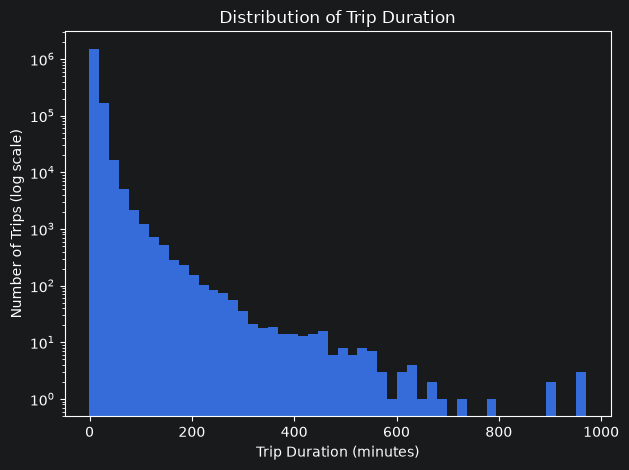

In [35]:
ax = (df["DURATION"] / 60).plot(
    kind="hist",
    bins=50,
    title="Distribution of Trip Duration",
    xlabel="Trip Duration (minutes)"
)

ax.set_yscale("log")
ax.set_ylabel("Number of Trips (log scale)")
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "duration_distribution.png", bbox_inches="tight")
plt.show()

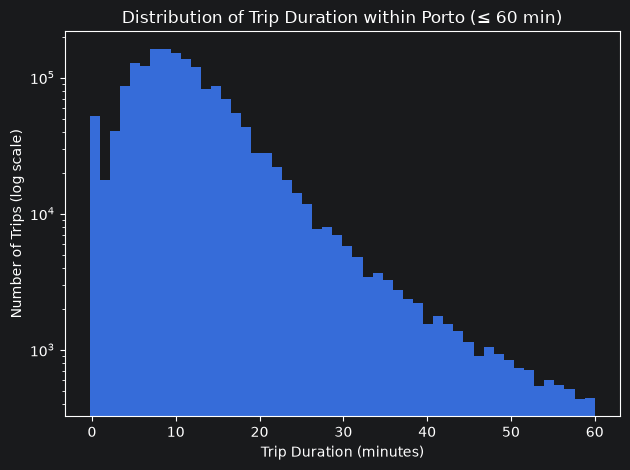

In [36]:
duration_min = df["DURATION"] / 60

duration_min = duration_min[duration_min <= MAX_PORTO_TRIP_DURATION_MINUTES]

ax = duration_min.plot(
    kind="hist",
    bins=50,
    title="Distribution of Trip Duration within Porto (≤ 60 min)",
    xlabel="Trip Duration (minutes)"
)

ax.set_yscale("log")
ax.set_ylabel("Number of Trips (log scale)")
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "porto_duration_distribution.png", bbox_inches="tight")
plt.show()

## 9. Distribution of Average Speed per Trip

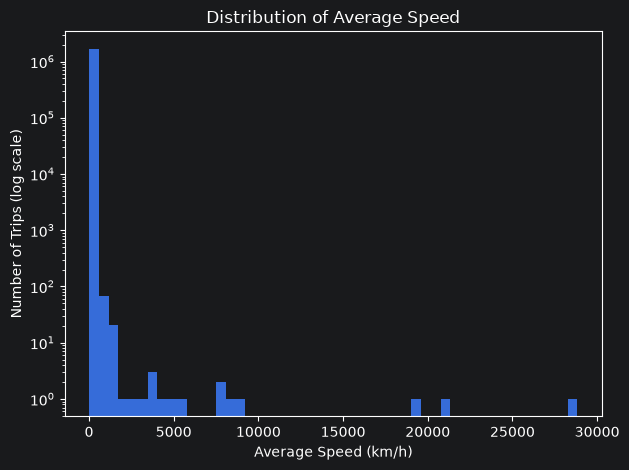

In [37]:
ax = (df["AVERAGE_SPEED"]).plot(
    kind="hist",
    bins=50,
    title="Distribution of Average Speed",
    xlabel="Average Speed (km/h)"
)

ax.set_yscale("log")
ax.set_ylabel("Number of Trips (log scale)")
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "average_speed_distribution.png", bbox_inches="tight")
plt.show()

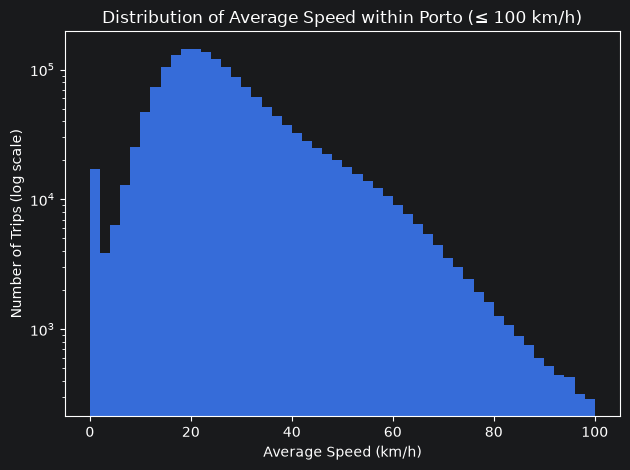

In [38]:
average_speed_min = df["AVERAGE_SPEED"][df["AVERAGE_SPEED"] <= MAX_PORTO_AVERAGE_SPEED_KMH]

ax = average_speed_min.plot(
    kind="hist",
    bins=50,
    title="Distribution of Average Speed within Porto (≤ 100 km/h)",
    xlabel="Average Speed (km/h)"
)

ax.set_yscale("log")
ax.set_ylabel("Number of Trips (log scale)")
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "porto_average_speed_distribution.png", bbox_inches="tight")
plt.show()

## 10. Number of Trips per Taxi

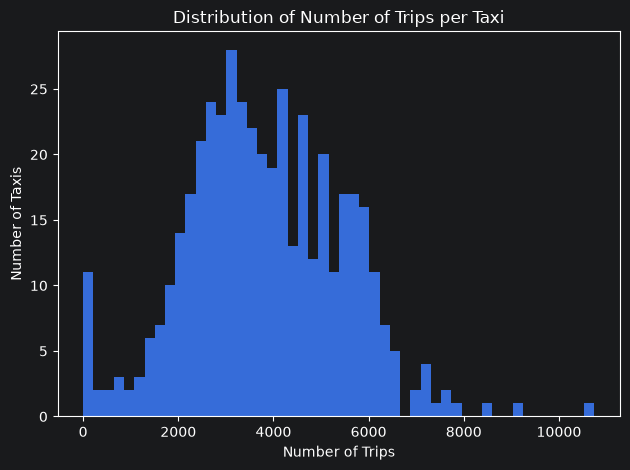

In [39]:
trips_per_taxi = df.groupby("TAXI_ID").size()

trips_per_taxi.plot(
    kind="hist",
    bins=50,
    title="Distribution of Number of Trips per Taxi",
    xlabel="Number of Trips",
    ylabel="Number of Taxis"
)
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "number_of_trips_per_taxi.png", bbox_inches="tight")
plt.show()

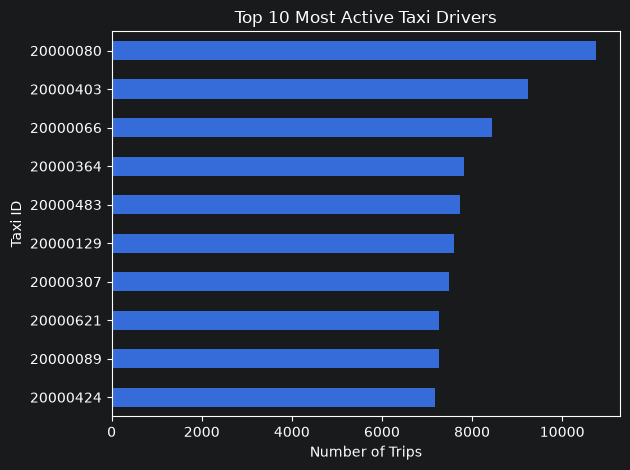

In [40]:
top_taxis = df["TAXI_ID"].value_counts().head(10)

top_taxis.sort_values().plot(
    kind="barh",
    title="Top 10 Most Active Taxi Drivers",
    xlabel="Number of Trips",
    ylabel="Taxi ID"
)
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "most_active_taxi_drivers.png", bbox_inches="tight")
plt.show()

## 11. Heatmaps

### 11.1 Pickup and Drop-off Location Heatmap

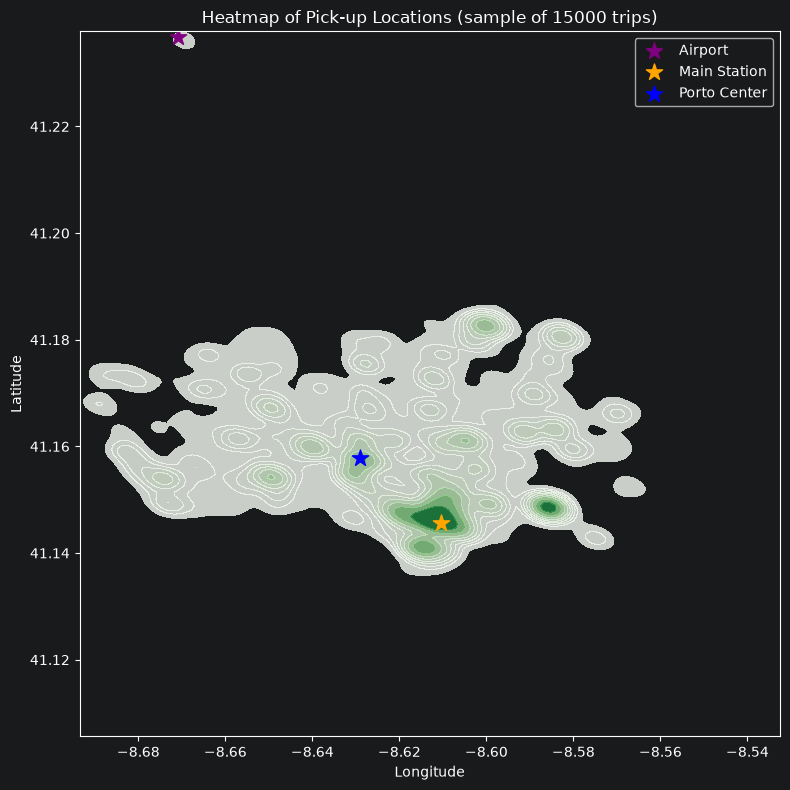

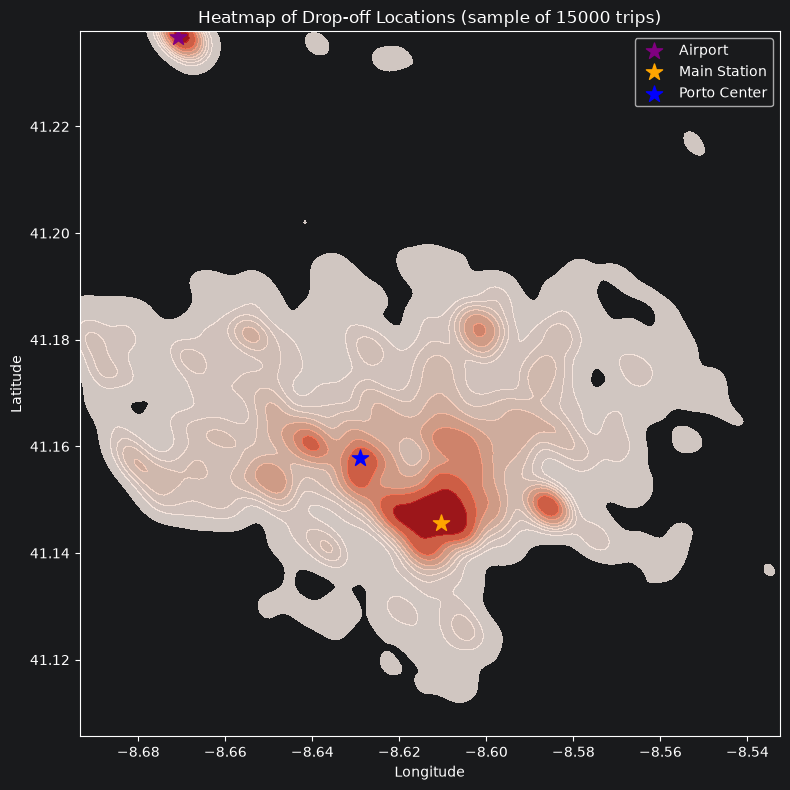

In [41]:
sample_df = df[df["MISSING_DATA"] == False].sample(SUBSET_SIZE, random_state=42)

start_points = []
end_points = []
for polyline in sample_df["POLYLINE"]:
    if polyline:
        start_points.append(polyline[0])
        end_points.append(polyline[-1])
lons_start = np.array([pt[0] for pt in start_points])
lats_start = np.array([pt[1] for pt in start_points])
lons_end = np.array([pt[0] for pt in end_points])
lats_end = np.array([pt[1] for pt in end_points])

min_lon, max_lon = np.percentile(np.concatenate([lons_start, lons_end]), 0.5), np.percentile(np.concatenate([lons_start, lons_end]), 99.5)
min_lat, max_lat = np.percentile(np.concatenate([lats_start, lats_end]), 0.5), np.percentile(np.concatenate([lats_start, lats_end]), 99.5)

pickup_mask = (min_lon <= lons_start) & (lons_start <= max_lon) & (min_lat <= lats_start) & (lats_start <= max_lat)
dropoff_mask = (min_lon <= lons_end) & (lons_end <= max_lon) & (min_lat <= lats_end) & (lats_end <= max_lat)

plt.figure(figsize=(8, 8))
sns.kdeplot(
    x=lons_start[pickup_mask], y=lats_start[pickup_mask], cmap="Greens", fill=True, bw_adjust=0.5, alpha=0.8,
    clip=((min_lon, max_lon), (min_lat, max_lat)),
    label="Pickup"
)
plt.scatter(AIRPORT[0], AIRPORT[1], color="purple", s=150, marker="*", label="Airport")
plt.scatter(MAIN_STATION[0], MAIN_STATION[1], color="orange", s=150, marker="*", label="Main Station")
plt.scatter(PORTO_CENTER[0], PORTO_CENTER[1], color="blue", s=150, marker="*", label="Porto Center")
plt.title(f"Heatmap of Pick-up Locations (sample of {SUBSET_SIZE} trips)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend()
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "pickup_locations_heatmap.png", bbox_inches="tight")
plt.show()

plt.figure(figsize=(8, 8))
sns.kdeplot(
    x=lons_end[dropoff_mask], y=lats_end[dropoff_mask], cmap="Reds", fill=True, bw_adjust=0.5, alpha=0.8,
    clip=((min_lon, max_lon), (min_lat, max_lat)), label="Drop-off")
plt.scatter(AIRPORT[0], AIRPORT[1], color="purple", s=150, marker="*", label="Airport")
plt.scatter(MAIN_STATION[0], MAIN_STATION[1], color="orange", s=150, marker="*", label="Main Station")
plt.scatter(PORTO_CENTER[0], PORTO_CENTER[1], color="blue", s=150, marker="*", label="Porto Center")
plt.title(f"Heatmap of Drop-off Locations (sample of {SUBSET_SIZE} trips)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend()
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "dropoff_locations_heatmap.png", bbox_inches="tight")
plt.show()

### 11.2 Heatmap of Taxi Trajectories

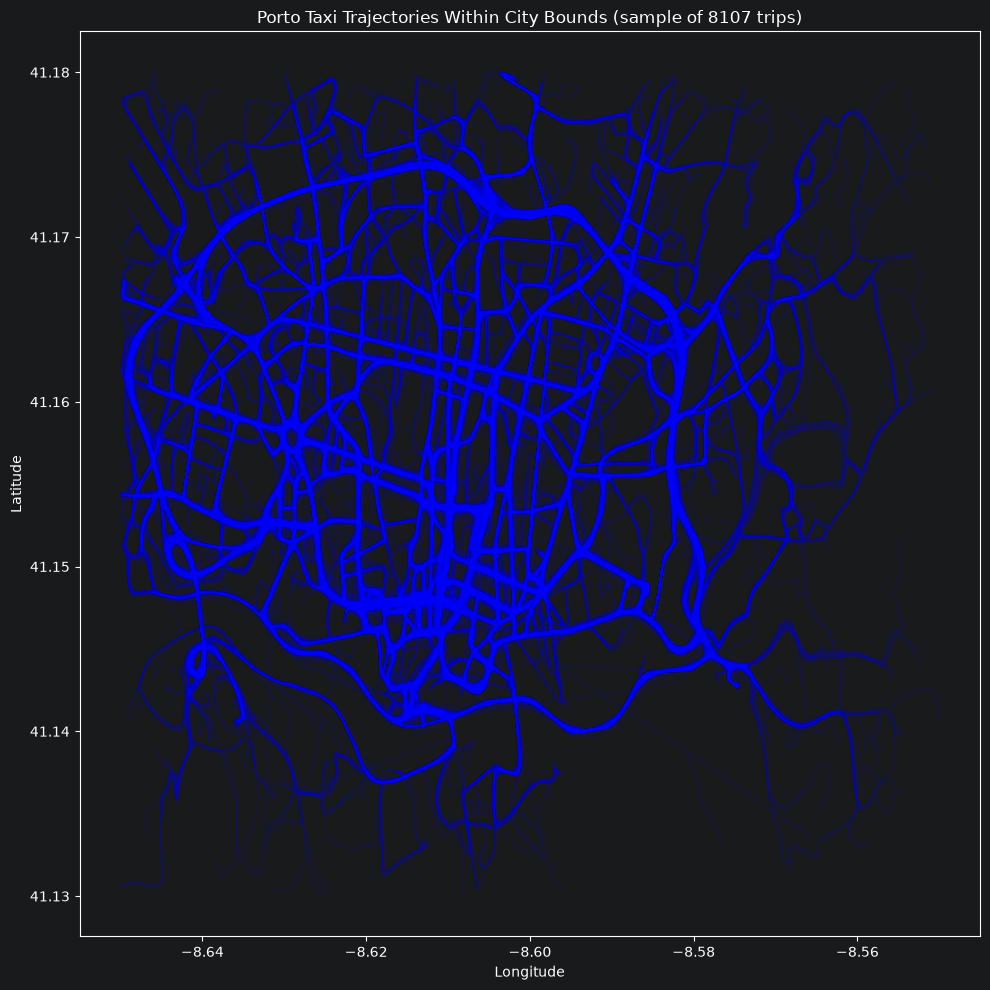

1054 trips with jumps > 0.50 km (> 120 km/h) within city bounds (out of 15000)


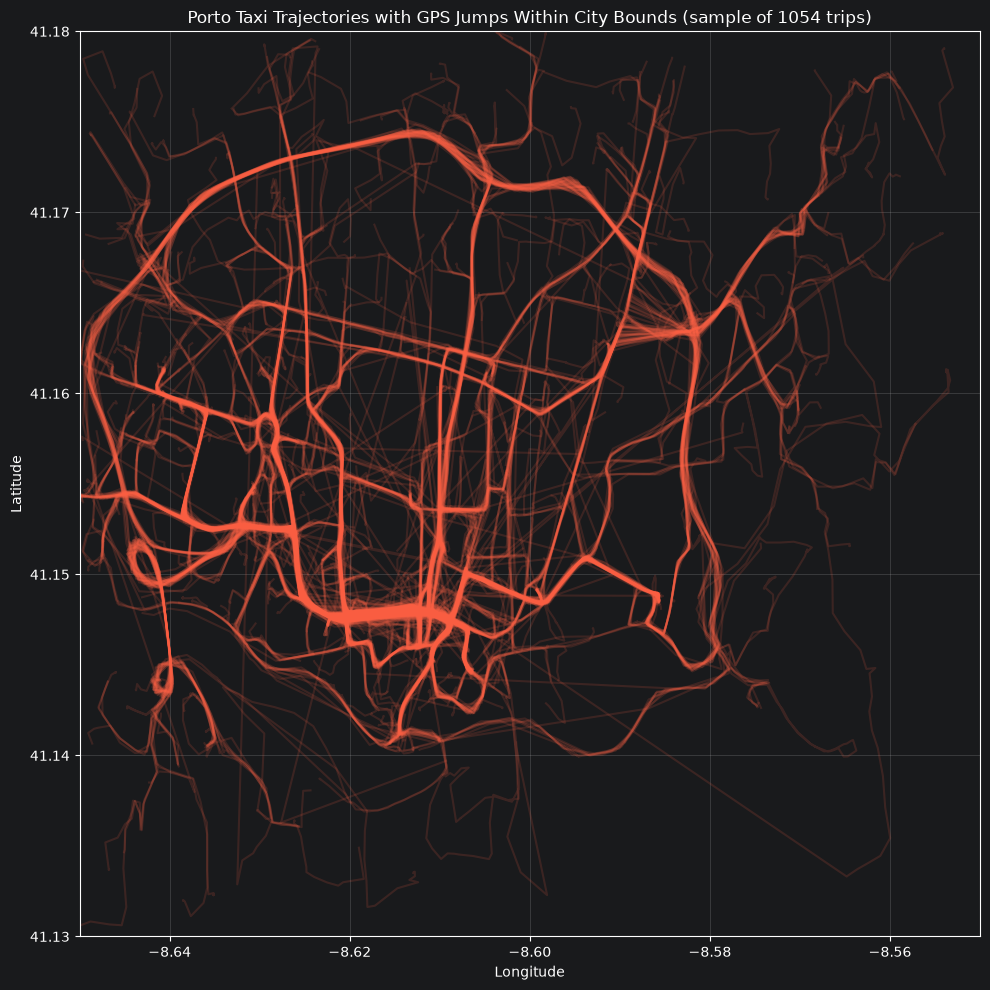

In [42]:
plt.figure(figsize=(10, 10))
count = 0

subset_df = df[df["MISSING_DATA"] == False].sample(SUBSET_SIZE, random_state=42).copy()

# Plot complete trips within city center bounds
for polyline in subset_df["POLYLINE"]:
    if polyline:
        lons, lats = zip(*polyline)
        if is_within_city_bounds(polyline):
            plt.plot(lons, lats, alpha=0.1, color="blue")
            count += 1
plt.title(f"Porto Taxi Trajectories Within City Bounds (sample of {count} trips)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "complete_taxi_trajectories.png", bbox_inches="tight")
plt.show()

# Inspect unusually large jumps in complete trips within city bounds.
# A jump is a segment faster than the speed limit used in the speed anomaly analysis (13.4):
# 120 km/h over a 15-second interval is a distance of 0.5 km
max_jump_km = SPEED_LIMIT_KMH * GPS_INTERVAL_SECONDS / 3600

subset_df["HAS_JUMP"] = subset_df["POLYLINE"].apply(lambda x: has_large_jump(x, max_jump_km=max_jump_km))
subset_df["WITHIN_CITY"] = subset_df["POLYLINE"].apply(is_within_city_bounds)

jump_city_df = subset_df[(subset_df["HAS_JUMP"]) & (subset_df["WITHIN_CITY"])].copy()

print(
    f"{len(jump_city_df)} trips with jumps > {max_jump_km:.2f} km "
    f"(> {SPEED_LIMIT_KMH} km/h) within city bounds (out of {len(subset_df)})"
)

plt.figure(figsize=(10, 10))
for coords in jump_city_df["POLYLINE"]:
    if coords:
        lons, lats = zip(*coords)
        plt.plot(lons, lats, alpha=0.15, color="tomato")

plt.title(
    f"Porto Taxi Trajectories with GPS Jumps Within City Bounds (sample of {len(jump_city_df)} trips)"
)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.xlim(CITY_BOUNDS[0], CITY_BOUNDS[1])
plt.ylim(CITY_BOUNDS[2], CITY_BOUNDS[3])
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "gps_jumps_trajectories.png", bbox_inches="tight")
plt.show()

### 11.3 Heatmap of Trafic Congestion

In [43]:
congestion_candidates = df[
    (df["MISSING_FLAG"] == False)
]
congestion_sample = congestion_candidates.sample(
    min(SUBSET_SIZE, len(congestion_candidates)),
    random_state=42
)

congestion_heat_points = []
for polyline in congestion_sample["POLYLINE"]:
    low_movement_segments = []

    for segment_index, (point_a, point_b) in enumerate(zip(polyline, polyline[1:])):
        segment_distance = haversine(point_a, point_b)
        if segment_distance <= CONGESTION_DISTANCE_KM:
            low_movement_segments.append(segment_index)

    if not low_movement_segments:
        continue

    run_start = low_movement_segments[0]
    previous_segment = run_start

    for segment_index in low_movement_segments[1:] + [None]:
        is_same_run = (
            segment_index is not None
            and segment_index == previous_segment + 1
        )

        if is_same_run:
            previous_segment = segment_index
            continue

        run_length = previous_segment - run_start + 1
        dwell_seconds = run_length * 15
        if dwell_seconds >= CONGESTION_MIN_DURATION_SECONDS:
            for current_index in range(run_start, previous_segment + 1):
                point_a = polyline[current_index]
                point_b = polyline[current_index + 1]
                midpoint_lon = (point_a[0] + point_b[0]) / 2
                midpoint_lat = (point_a[1] + point_b[1]) / 2
                congestion_heat_points.append(
                    [midpoint_lat, midpoint_lon, dwell_seconds]
                )

        if segment_index is not None:
            run_start = segment_index
            previous_segment = segment_index

porto_map = folium.Map(
    location=[41.1579, -8.6291],
    zoom_start=13,
    tiles="OpenStreetMap",
    control_scale=True
)

if congestion_heat_points:
    HeatMap(
        congestion_heat_points,
        radius=18,
        blur=24,
        min_opacity=0.35,
        max_zoom=16,
        name="Potential congestion hotspots"
    ).add_to(porto_map)

folium.Marker(
    [MAIN_STATION[1], MAIN_STATION[0]],
    tooltip="Main Station",
    icon=folium.Icon(color="blue", icon="train", prefix="fa")
).add_to(porto_map)
folium.Marker(
    [PORTO_CENTER[1], PORTO_CENTER[0]],
    tooltip="Porto Center",
    icon=folium.Icon(color="green", icon="info-sign")
).add_to(porto_map)
folium.Marker(
    [AIRPORT[1], AIRPORT[0]],
    tooltip="Airport",
    icon=folium.Icon(color="purple", icon="plane", prefix="fa")
).add_to(porto_map)

folium.LayerControl().add_to(porto_map)
porto_map.save(RESULT_FOLDER + "congestion_heatmap.html")
porto_map

## 12. Data Quality

### 12.1 Missing Values

In [44]:
print(df.columns)

Index(['TRIP_ID', 'CALL_TYPE', 'ORIGIN_CALL', 'ORIGIN_STAND', 'TAXI_ID',
       'TIMESTAMP', 'DAY_TYPE', 'MISSING_DATA', 'POLYLINE', 'DATETIME', 'DATE',
       'GPS_POINTS', 'DURATION', 'DISTANCE', 'AVERAGE_SPEED', 'MISSING_FLAG',
       'EMPTY_POLYLINE', 'MISSING_LOCATION'],
      dtype='str')


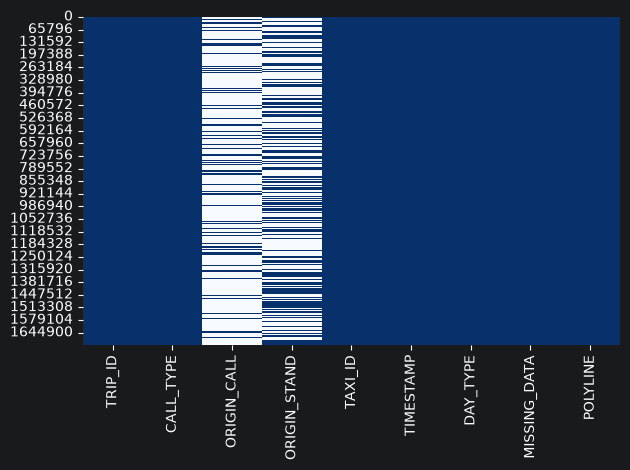

In [45]:
original_columns = [
    "TRIP_ID",
    "CALL_TYPE",
    "ORIGIN_CALL",
    "ORIGIN_STAND",
    "TAXI_ID",
    "TIMESTAMP",
    "DAY_TYPE",
    "MISSING_DATA",
    "POLYLINE"
]

sns.heatmap(
    df[original_columns].isnull(),
    cbar=False,
    cmap="Blues_r"
)

plt.tight_layout()
plt.savefig(RESULT_FOLDER + "missing_values_heatmap.png", bbox_inches="tight")
plt.show()

### 12.2 Duplicate Values

In [ ]:
trip_id_duplicate_mask = df["TRIP_ID"].duplicated(keep=False)
trip_id_duplicate_values = df.loc[trip_id_duplicate_mask, "TRIP_ID"].nunique()
trip_id_duplicate_rows = trip_id_duplicate_mask.sum()
trip_id_extra_rows = df["TRIP_ID"].duplicated().sum()

duplicate_check_df = df.copy()
duplicate_check_df["POLYLINE"] = duplicate_check_df["POLYLINE"].apply(
	lambda polyline: tuple(tuple(point) for point in polyline)
)

exact_duplicate_mask = duplicate_check_df.duplicated(keep=False)
exact_duplicate_values = duplicate_check_df.loc[exact_duplicate_mask].drop_duplicates().shape[0]
exact_duplicate_rows = exact_duplicate_mask.sum()
exact_duplicate_extra_rows = duplicate_check_df.duplicated().sum()

print(f"TRIP_ID values appearing more than once: {trip_id_duplicate_values}")
print(f"Rows belonging to duplicated TRIP_ID values: {trip_id_duplicate_rows}")
print(f"Extra rows caused by duplicated TRIP_ID values: {trip_id_extra_rows}")
print(f"Exact duplicate trip groups: {exact_duplicate_values}")
print(f"Rows belonging to exact duplicate groups: {exact_duplicate_rows}")
print(f"Extra rows caused by exact duplicates: {exact_duplicate_extra_rows}")

In [ ]:
missing_by_taxi = (
    df.groupby("TAXI_ID")
    .agg(
        total_trips=("TRIP_ID", "size"),
        missing_trips=("MISSING_LOCATION", "sum")
    )
    .assign(fraction_missing=lambda data: data["missing_trips"] / data["total_trips"])
    .query("missing_trips > 0")
    .sort_values("fraction_missing", ascending=False)
    .reset_index()
)

missing_by_taxi = missing_by_taxi.head(10)
display(missing_by_taxi)

### 12.3 Inconsistent Values

In [ ]:
print(
    ((df["CALL_TYPE"] == "A") & df["ORIGIN_CALL"].isna()).sum(),
    "A trips have missing ORIGIN_CALL"
)

print(
    ((df["CALL_TYPE"] != "A") & df["ORIGIN_CALL"].notna()).sum(),
    "non-A trips incorrectly have ORIGIN_CALL"
)

print(
    ((df["CALL_TYPE"] == "B") & df["ORIGIN_STAND"].isna()).sum(),
    "B trips have missing ORIGIN_STAND"
)

print(
    ((df["CALL_TYPE"] != "B") & df["ORIGIN_STAND"].notna()).sum(),
    "non-B trips incorrectly have ORIGIN_STAND"
)

In [ ]:
years = pd.to_datetime(df["DATE"]).dt.year.unique()

pt_holidays = holidays.Portugal(years=years)

holiday_dates = set(pt_holidays.keys())

day_before_holiday = {
    day - pd.Timedelta(days=1)
    for day in holiday_dates
}
df["EXPECTED_DAY_TYPE"] = df["DATE"].apply(get_correct_day_type, args=(holiday_dates, day_before_holiday))

day_type_names = {
    "A": "Normal days",
    "B": "Holidays",
    "C": "Days before holidays"
}

for day_type in ["A", "B", "C"]:

    df_expected = df[df["EXPECTED_DAY_TYPE"] == day_type]

    incorrect = (df_expected["DAY_TYPE"] != day_type).sum()

    print(
        incorrect,
        "out of",
        len(df_expected),
        f"{day_type_names[day_type]} are incorrectly marked"
    )

print()

for day_type in ["A", "B", "C"]:

    df_marked = df[df["DAY_TYPE"] == day_type]

    incorrect = (df_marked["EXPECTED_DAY_TYPE"] != day_type).sum()

    print(
        incorrect,
        "out of",
        len(df_marked),
        f"trips marked {day_type} should have a different DAY_TYPE"
    )

marked_counts = (
    df["DAY_TYPE"]
    .value_counts()
    .reindex(["A", "B", "C"], fill_value=0)
)

correct_counts = (
    df["EXPECTED_DAY_TYPE"]
    .value_counts()
    .reindex(["A", "B", "C"], fill_value=0)
)

comparison = pd.DataFrame({
    "Marked in dataset": marked_counts,
    "Correct day type": correct_counts
})

comparison.index = comparison.index.map({
    "A": "A: Normal day (workday or weekend)",
    "B": "B: Holiday or special day",
    "C": "C: Day before a holiday"
})

ax = comparison.plot(
    kind="bar",
    figsize=(10, 5),
    title="Reported vs Correct Day Types",
    xlabel="Day Type",
    ylabel="Number of Trips",
    rot=0
)

ax.ticklabel_format(style="plain", axis="y")

plt.tight_layout()
plt.savefig(RESULT_FOLDER + "day_type_validation.png", bbox_inches="tight")
plt.show()

In [ ]:
missing_data_marked = df[df["MISSING_FLAG"]]
empty_polyline = df[df["EMPTY_POLYLINE"]]
both = df[df["MISSING_FLAG"] & df["EMPTY_POLYLINE"]]

missing_data_all = df["MISSING_LOCATION"].sum()

print(len(missing_data_marked), "rows are marked as missing data")
print(len(empty_polyline), "rows have empty POLYLINE, aka no location data")
print(missing_data_all, "rows are missing location data")
print(f"The missing rows make up {missing_data_all / len(df) * 100:.2f}% of the dataset")
print(len(both), "rows have both MISSING_DATA == True and empty POLYLINE")

labels = ["Valid", "Empty Polyline", "Missing Data == True"]

numbers = [
    (~df["MISSING_LOCATION"]).sum(),
    df["EMPTY_POLYLINE"].sum(),
    df["MISSING_FLAG"].sum()
]

missing_location_data = pd.Series(numbers, index=labels)

ax = missing_location_data.plot(
    kind="bar",
    figsize=(10, 4),
    title="Missing Location Data",
    xlabel="Data Status",
    ylabel="Number of Rows",
    logy=True,
    rot=0
)

ax.grid(False)

plt.tight_layout()
plt.savefig(RESULT_FOLDER + "missing_location_data.png", bbox_inches="tight")
plt.show()

## 13. Outlier Detection

In [ ]:
outlier_df = df[
    (~df["MISSING_LOCATION"])
    & (df["GPS_POINTS"] >= 2)
].copy()

outlier_summary = {}

print(len(outlier_df), "of", len(df), "trips are used in the outlier analysis")

### 13.1 Duration

In [ ]:
outlier_summary["DURATION (min)"] = plot_outlier_boxplot(
    outlier_df["DURATION"] / 60,
    title="Boxplot of Trip Duration (IQR Outliers)",
    xlabel="Trip Duration (minutes)",
    output_path=RESULT_FOLDER + "duration_boxplot.png"
)

display(pd.Series(outlier_summary["DURATION (min)"]).round(2))

### 13.2 Distance

In [ ]:
outlier_summary["DISTANCE (km)"] = plot_outlier_boxplot(
    outlier_df["DISTANCE"],
    title="Boxplot of Trip Distance (IQR Outliers)",
    xlabel="Trip Distance (km)",
    output_path=RESULT_FOLDER + "distance_boxplot.png"
)

display(pd.Series(outlier_summary["DISTANCE (km)"]).round(2))

### 13.3 Average Speed

In [ ]:
outlier_summary["AVERAGE_SPEED (km/h)"] = plot_outlier_boxplot(
    outlier_df["AVERAGE_SPEED"],
    title="Boxplot of Average Speed (IQR Outliers)",
    xlabel="Average Speed (km/h)",
    output_path=RESULT_FOLDER + "average_speed_boxplot.png"
)

display(pd.Series(outlier_summary["AVERAGE_SPEED (km/h)"]).round(2))

In [ ]:
display(pd.DataFrame(outlier_summary).T.round(2))

### 13.4 Speed Anomalies

In [ ]:
features = pd.concat(
    [
        compute_speed_features(
            df["POLYLINE"].iloc[start:start + SPEED_CHUNK_SIZE].tolist(),
            speed_limit_kmh=SPEED_LIMIT_KMH,
            interval_seconds=GPS_INTERVAL_SECONDS
        )
        for start in range(0, len(df), SPEED_CHUNK_SIZE)
    ],
    ignore_index=True
)
features.index = df.index

speed_status = pd.Series(
    np.select(
        [
            df["EMPTY_POLYLINE"],
            df["MISSING_FLAG"],
            features["valid_segments"].eq(0)
        ],
        [
            "Empty polyline",
            "MISSING_DATA = True",
            "No valid segments"
        ],
        default="Valid"
    ),
    index=df.index
)
valid_speed = speed_status.eq("Valid")

speed_columns = [
    "max_segment_speed",
    "speed_violation_count",
    "speed_violation_ratio",
    "p95_segment_speed"
]

for column in speed_columns:
    df[column] = features[column].where(valid_speed)

df["speed_violation_count"] = df["speed_violation_count"].round().astype("Int64")

# TODO: Decide the flagging rule after inspecting the plots below
df["speed_anomaly_flag"] = pd.Series(pd.NA, index=df.index, dtype="boolean")

speed_df = df.loc[valid_speed]

display(df[["TRIP_ID", "GPS_POINTS", *speed_columns, "speed_anomaly_flag"]].head())

In [ ]:
count_bins = [-0.5, *np.arange(0.5, 11), 20.5, 50.5, np.inf]
count_labels = [str(count) for count in range(11)] + ["11–20", "21–50", "> 50"]

violation_count_groups = plot_share_bar_chart(
    speed_df["speed_violation_count"].astype(int),
    bins=count_bins,
    labels=count_labels,
    title=(
        f"Number of Taxi Trips per Speed Violation Count (speed between segments > {SPEED_LIMIT_KMH} km/h)"
    ),
    xlabel="Number of Violating Segments",
    output_path=RESULT_FOLDER + "speed_violation_count_distribution.png"
)

In [ ]:
ratio_bins = [-1e-9, 0, *range(1, 11), 20, 50, 100]
ratio_labels = ["0%"] + [f"{low}–{low + 1}%" for low in range(10)] + ["10–20%", "20–50%", "50–100%"]

violation_ratio_groups = plot_share_bar_chart(
    speed_df["speed_violation_ratio"] * 100,
    bins=ratio_bins,
    labels=ratio_labels,
    title=(
        f"Number of Taxi Trips per Speed Violation Ratio (share of segments with speed > {SPEED_LIMIT_KMH} km/h)"
    ),
    xlabel="Share of Violating Segments in the Trip",
    output_path=RESULT_FOLDER + "speed_violation_ratio_distribution.png",
    color="#F58518"
)

In [ ]:
speed_thresholds = [100, 120, 150, 180, 200]

max_speed_bins = [0, 20, 40, 60, 80, 100, 120, 150, 180, 200, 300, 500, np.inf]
max_speed_labels = [
    "0–20", "20–40", "40–60", "60–80", "80–100", "100–120",
    "120–150", "150–180", "180–200", "200–300", "300–500", "> 500"
]

max_speed_groups = plot_share_bar_chart(
    speed_df["max_segment_speed"],
    bins=max_speed_bins,
    labels=max_speed_labels,
    title=(
        "Number of Taxi Trips per Maximum Segment Speed (highest speed between segments in the trip)"
    ),
    xlabel="Maximum Segment Speed (km/h)",
    output_path=RESULT_FOLDER + "max_segment_speed_distribution.png",
    color="#54A24B",
    highlight_from="120–150",
    highlight_color="#E45756"
)

In [ ]:
print(f"Total number of trips: {len(df):,}")
print(f"Trips with valid speed calculations: {len(speed_df):,} ({100 * len(speed_df) / len(df):.2f}%)")

speed_status_summary = (
    speed_status.value_counts()
    .rename_axis("Speed calculation status")
    .reset_index(name="Trips")
)

speed_status_summary["Share of all trips (%)"] = (
    100 * speed_status_summary["Trips"] / len(df)
)

display(
    speed_status_summary.style
    .format({"Share of all trips (%)": "{:.2f}"})
    .hide(axis="index")
)

display(speed_status_summary.round(2))

count_thresholds = [0, 1, 2, 3, 5, 10]
violation_count_summary = summarize_thresholds(
    speed_df["speed_violation_count"],
    count_thresholds,
    [f"speed_violation_count > {threshold}" for threshold in count_thresholds]
)

ratio_thresholds = [0, 0.01, 0.02, 0.05, 0.10, 0.20]
violation_ratio_summary = summarize_thresholds(
    speed_df["speed_violation_ratio"],
    ratio_thresholds,
    [f"speed_violation_ratio > {threshold:.0%}" for threshold in ratio_thresholds]
)

max_speed_summary = summarize_thresholds(
    speed_df["max_segment_speed"],
    speed_thresholds,
    [f"max_segment_speed > {threshold} km/h" for threshold in speed_thresholds]
)

display(violation_count_summary.round(2))
display(violation_ratio_summary.round(2))
display(max_speed_summary.round(2))

speed_descriptive_statistics = (
    speed_df[speed_columns]
    .astype(float)
    .describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 0.999])
    .T
)
display(speed_descriptive_statistics.round(3))